# Cálculo de NDVI

Vamos a trabajar con imágenes del satélite **Sentinel-2**, del programa Copernicus. Sentinel-2 registra la luz que refleja la superficie terrestre en 13 **bandas** del espectro, y no todas tienen la misma resolución:

| Resolución | Bandas |
|---|---|
| 10 m | B02 (azul), B03 (verde), **B04 (rojo)**, **B08 (infrarrojo cercano)** |
| 20 m | B05, B06 y B07 (borde del rojo), B8A (infrarrojo cercano angosto), B11 y B12 (infrarrojo de onda corta) |
| 60 m | B01 (aerosoles), B09 (vapor de agua), B10 (cirros; solo en el producto L1C) |

En este ejercicio vas a visualizar las bandas **Roja (B04)** e **Infrarrojo Cercano (B08)** y, a partir de ellas, calcular y analizar el **NDVI (Normalized Difference Vegetation Index)**, un índice muy usado para estudiar el estado de la vegetación. Las dos bandas tienen la resolución más fina del satélite: si se descargan a su resolución original, cada píxel cubre un cuadrado de 10 m x 10 m, es decir, **100 m²** de superficie. Al descargar se puede elegir una resolución menor (píxeles más grandes) para que los archivos ocupen menos.

Antes del taller, completá la primera sección (**Configuración**).

## Configuración

1. Instalá las dependencias siguiendo la sección **Instalar Dependencias** del `README.md` del repositorio: ahí se explica cómo crear un entorno de Python e instalar los paquetes de `requirements.txt`.
2. Abrí este notebook con ese entorno y ejecutá la celda siguiente. Si imprime las versiones de las librerías sin errores, la configuración está lista.

Las imágenes que vamos a usar ya vienen en la carpeta `class/raw/` del repositorio.


In [1]:
# Importar librerías
import rasterio
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import re

# Mostrar las versiones de las librerías para comprobar que estén instaladas
print(f"Versión de rasterio: {rasterio.__version__}")
print(f"Versión de numpy: {np.__version__}")

Versión de rasterio: 1.4.3
Versión de numpy: 2.3.4


Documentación, ejemplos y explicaciones para cada librería que vas a usar:

- [**rasterio**](https://rasterio.readthedocs.io/): Para leer y procesar datos ráster.
- [**numpy**](https://numpy.org/doc/): Para operaciones numéricas eficientes.
- [**pathlib**](https://docs.python.org/3/library/pathlib.html): Para manejar rutas de archivos de forma cómoda y moderna.
- [**matplotlib**](https://matplotlib.org/stable/contents.html): Para visualizar datos e imágenes.
- [**re (Expresiones regulares)**](https://docs.python.org/3/library/re.html): Para trabajar con patrones de texto.

## Guía paso a paso para el análisis geoespacial

### Paso 1: Acceso a imágenes del Sentinel

- La **[SentiWiki](https://sentiwiki.copernicus.eu/web/sentiwiki)** tiene información de los satélites, los diseños y los datos que adquieren. 
- Acceso a los datos del Sentinel: [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu/).
- Para buscar y descargar imágenes desde el navegador: [Copernicus Browser](https://browser.dataspace.copernicus.eu/).

Las imágenes de este ejercicio ya están descargadas en `class/raw/`. En este paso y el siguiente ves de dónde salen y cómo se obtienen: lo vas a necesitar al final, para repetir el análisis con tus propias imágenes. 

Para descargar una imagen se define el área de interés (AOI) con coordenadas (latitud y longitud) y se eligen las bandas que hacen falta.

**¿Qué es lo que realmente estás abriendo? Un archivo ráster.**

Una imagen satelital se puede pensar como una grilla (matriz) donde cada píxel representa un pequeño pedazo de la superficie terrestre y almacena un valor de reflectancia en una determinada banda del espectro (Rojo, NIR, Azul, Verde, etc.).

Los archivos `.tiff` (GeoTIFF) suelen incluir además metadatos importantes:
- Sistema de referencia de coordenadas.
- Resolución espacial.
- Número de bandas.
- Información adicional sobre el sensor y el producto.

La idea es que entiendas qué estás manipulando antes de tirarle operaciones encima.

> Si todo esto te parece mucha teoría, quedate con la idea básica: “cada píxel es un numerito” y después ya le vamos agregando detalles.


### Paso 2: Descarga de bandas

Identificá y descargá las bandas necesarias para calcular el **NDVI**. Podés guardar tus imágenes junto a las existentes, en la misma carpeta (`class/raw/ndvi/`). En Sentinel-2 se usan:

- Banda **Roja** (B04).
- Banda **NIR** (Infrarrojo Cercano, B08).

Al descargar:

- Definí la ubicación exacta usando coordenadas (lat/long) o un polígono.
- En el Copernicus Browser, usá la descarga **Analytical** y elegí las bandas **B04** y **B08** en versión **Raw** (Sentinel-2 L2A).
- Elegí el formato **TIFF** con profundidad de **16 bits**: los valores quedan entre 0 y 65.535 (reflectancia × 65.535).
- Elegí la resolución. Las imágenes de `class/raw/ndvi/` se descargaron con la opción *MEDIUM*: sus píxeles miden unos **16 m** en lugar de los 10 m originales, y los archivos ocupan menos. Para este ejercicio alcanza.
- Podés usar `pathlib` para manejar rutas y mover/copiar archivos de forma ordenada.

**¿Qué es un píxel (“px”)?**

Es la unidad mínima de la imagen. Cada píxel cubre un área en el terreno (por ejemplo, 10 m x 10 m para ciertas bandas de Sentinel-2) y guarda un valor de reflectancia. 

**Reflectancia:** fracción de la luz del sol que llega a un área y que la superficie refleja. Vale 0 si no refleja nada y 1 si refleja toda.

Cuando uses `rasterio.open(...)`, fijate en atributos como:

- `type(src).__name__`
- `src.width`, `src.height`
- `src.crs` (sistema de coordenadas)
- `src.count` (número de bandas)
- `src.meta` (diccionario con metadatos)
- la forma de `src.read()` y `src.read(1)`


In [2]:
# Bandas de Sentinel-2 L2A descargadas para el ejercicio
directory_path = Path('../raw/ndvi')

# Nombres de los archivos TIFF de la carpeta
for file_path in directory_path.glob("*.tiff"):
    print(file_path)
print('-' * 20)

# Elegimos un archivo para explorarlo, por ejemplo la banda roja (B04)
file_path = next(directory_path.glob("*B04*.tiff"))
print('Archivo elegido:', file_path.name)
print('*' * 20)

# ............................
# Solución:
# ............................
with rasterio.open(file_path) as src:
    print(f"Explorando {type(src).__name__}: {file_path.name}")
    print(f" - Ancho (width): {src.width}")
    print(f" - Alto (height): {src.height}")
    print(f" - Sistema de coordenadas (CRS): {src.crs}")
    print(f" - Límites (bounds): {src.bounds}")
    print(f" - Número de bandas: {src.count}")
    print(" - Índices de las bandas:", src.indexes)
    print(f" - Metadatos: {src.meta}")
    print(f" - Contenido ({type(src.read()).__name__}): {src.read().shape} con read() y {src.read(1).shape} con read(1)")
    print(" - Etiquetas (tags):", src.tags(0))

../raw/ndvi/2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B08_(Raw).tiff
../raw/ndvi/2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B04_(Raw).tiff
--------------------
Archivo elegido: 2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B04_(Raw).tiff
********************
Explorando DatasetReader: 2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B04_(Raw).tiff
 - Ancho (width): 682
 - Alto (height): 413
 - Sistema de coordenadas (CRS): EPSG:4326
 - Límites (bounds): BoundingBox(left=-54.259586334228516, bottom=-34.6733821521891, right=-54.13702011108399, top=-34.61237177558771)
 - Número de bandas: 1
 - Índices de las bandas: (1,)
 - Metadatos: {'driver': 'GTiff', 'dtype': 'uint16', 'nodata': None, 'width': 682, 'height': 413, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"

### Paso 3: Explorar, caracterizar y visualizar los datos

Primero vas a definir una función que lea una banda desde un archivo `.tiff` y devuelva:

- Los datos de la banda como un array de `numpy`.
- Los metadatos asociados (por ejemplo, el perfil de `rasterio`).

Usá **rasterio**, una librería pensada para trabajar con ráster geoespaciales, y combinala con **numpy** para las operaciones numéricas. Convertí los datos a `float32`, ya que lo vas a necesitar para los cálculos posteriores.

In [3]:
def read_band(filename):
    """
    Lee la primera banda de un archivo TIFF.
    - Parámetros:
        filename (Path o str): ruta completa al archivo.
    - Devuelve: tupla (band_data, metadata)
        band_data (numpy.ndarray): valores de la banda, convertidos a float32.
        metadata (dict): metadatos del archivo.
    """

    #........................
    # Solución:
    #........................
    with rasterio.open(filename) as src:
        band_data = src.read(1).astype('float32')  # lee la primera banda
        metadata = src.meta                        # metadatos del archivo
        return band_data, metadata

Una vez implementada la función:

1. Probala leyendo una banda.
2. Inspeccioná el resultado usando:
   - `.min()`
   - `.max()`
   - `.shape`

Así te das una idea del rango de valores y del tamaño de la imagen.

La variable `fecha` elige qué imagen usar: así las bandas B04 y B08 salen siempre de la misma imagen. Si guardaste tus propias imágenes en la carpeta, cambiala por la fecha de las tuyas (aparece al principio del nombre de cada archivo).

In [22]:
directory_path = Path('../raw/ndvi')

# Fecha de la imagen a analizar (aparece al principio del nombre de cada archivo)
fecha = "2024-11-22"

for file_path in sorted(directory_path.glob(f"{fecha}*.tiff")):
    print(file_path.name)

    if "B08" in file_path.name:  # el archivo es la banda B08 (NIR)
        B08, _ = read_band(file_path)
        #.........................
        # Solución:
        #.........................
        print('- Forma de la banda:', B08.shape)
        print('- B08 máximo:', B08.max())
        print('- B08 mínimo:', B08.min())
        print('')

    elif "B04" in file_path.name:  # el archivo es la banda B04 (rojo)
        B04, _ = read_band(file_path)
        #.........................
        # Solución:
        #.........................
        print('- Forma de la banda:', B04.shape)
        print('- B04 máximo:', B04.max())
        print('- B04 mínimo:', B04.min())
        print('')


2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B04_(Raw).tiff
- Forma de la banda: (413, 682)
- B04 máximo: 43043.0
- B04 mínimo: 1226.0

2024-11-22-00:00_2024-11-22-23:59_Sentinel-2_L2A_B08_(Raw).tiff
- Forma de la banda: (413, 682)
- B08 máximo: 50174.0
- B08 mínimo: 1271.0



**¿Qué valor guarda cada píxel?** 
- Sentinel-2 mide la **reflectancia**: la fracción de la luz que refleja la superficie, entre 0 (nada) y 1 (toda). 
- Los TIFF de 16 bits que descargamos (Paso 2) la llevan al rango completo de 16 bits, de 0 a 65.535 ($=2^{16}-1$). 

Por ejemplo, un valor de 20.683 en la banda B08 equivale a una reflectancia de 20.683 / 65.535 ≈ 0,32.

Para la primera visualización usamos una **escala fija**, con todos los valores posibles del archivo: 
- `min_sentinel = 0`
- `max_sentinel = 65535`

Así las dos bandas se ven con la misma escala y sus colores se pueden comparar entre sí.

Visualizá las bandas. Podés usar `plt.imshow(...)` con un mapa de colores como `cmap="Reds_r"`, `cmap="magma"` u otro que te guste. Mostrá las imágenes una al lado de la otra (`plt.subplot(num_rows, num_cols, position)`), activá los ejes (`plt.axis("on")` de ser necesario) y tratá de interpretar qué ves en cada banda.

> Los ejes de estos mapas muestran **filas y columnas de píxeles**, no coordenadas geográficas. Para ver latitud y longitud habría que usar los límites del archivo (`src.bounds`), que exploraste en el Paso 2.


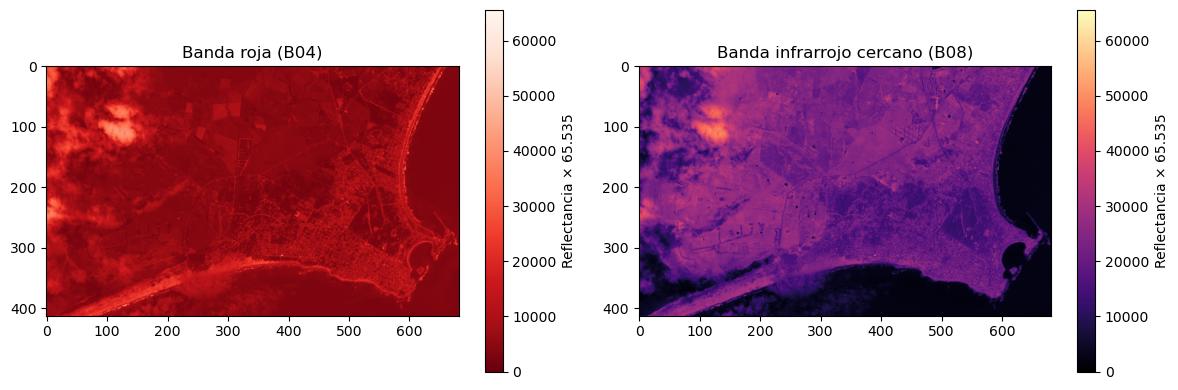

In [24]:
# Valores posibles de los TIFF de 16 bits (reflectancia re-escalada de 0 a 65.535)
min_sentinel = 0
max_sentinel = 65535

plt.figure(figsize=(12, 4))

# Visualizá las dos bandas lado a lado
plt.subplot(1, 2, 1)
# Banda roja (B04)
# .............................
# Solución:
# .............................
plt.imshow(B04, cmap="Reds_r", vmin=min_sentinel, vmax=max_sentinel)
plt.colorbar(label="Reflectancia × 65.535")
plt.title("Banda roja (B04)")

plt.subplot(1, 2, 2)
# Banda infrarrojo cercano (B08)
# .............................
# Solución:
# .............................
plt.imshow(B08, cmap="magma", vmin=min_sentinel, vmax=max_sentinel)
plt.colorbar(label="Reflectancia × 65.535")
plt.title("Banda infrarrojo cercano (B08)")

plt.tight_layout()
plt.show()

#### Escalas de visualización

Con la escala fija, los colores se reparten entre todos los valores posibles (0 a 65.535). Pero lo que nos interesa estudiar ocupa una parte chica de ese rango: la vegetación refleja:
- apenas un 3–10 % de la luz roja, y 
- un 20–45 % del infrarrojo cercano. 

Por eso casi toda la imagen queda en unos pocos tonos y cuesta distinguir detalles. Para aprovechar mejor los colores hay que ajustar la escala a los valores que realmente tiene la imagen:

1. **Mínimo–máximo:** la escala va del valor más bajo al más alto de cada banda (es lo que hace `plt.imshow` si no le indicamos `vmin` y `vmax`). Mejora algo, pero los extremos los fijan las superficies que menos y más reflejan: el **agua** y las sombras abajo, las **nubes** y la arena arriba. La vegetación sigue concentrada en un rango acotado.


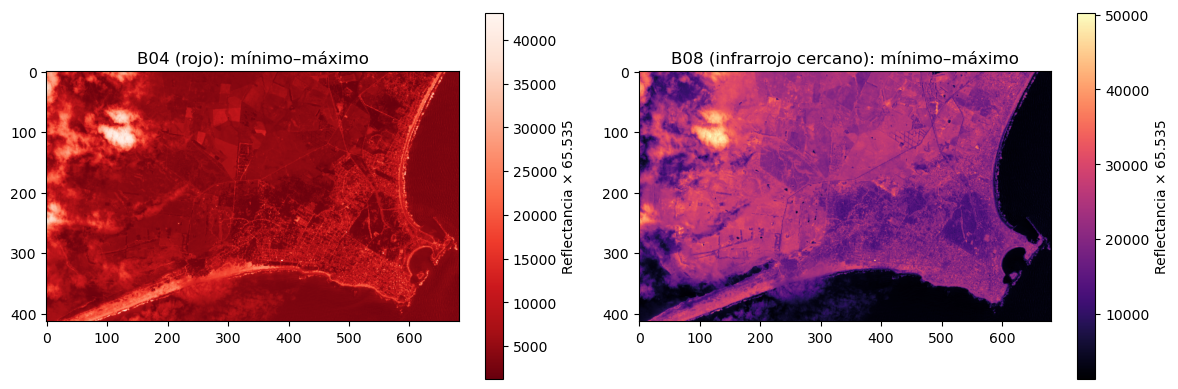

In [25]:
# Las dos bandas con escala mínimo–máximo
plt.figure(figsize=(12, 4))

for i, (name, band,cmap) in enumerate([("B04 (rojo)", B04, "Reds_r"), ("B08 (infrarrojo cercano)", B08, "magma")], start=1):
    plt.subplot(1, 2, i)
    plt.imshow(band, cmap=cmap)   # sin vmin ni vmax: escala mínimo–máximo
    plt.colorbar(label="Reflectancia × 65.535")
    plt.title(f"{name}: mínimo–máximo")

plt.tight_layout()
plt.show()

2. **Estiramiento por percentiles:** la escala va de un percentil inferior a uno superior de la banda. Los píxeles que quedan por debajo del inferior o por encima del superior, los **extremos**, se saturan en el color mínimo o máximo, y todos los colores se reparten entre los valores intermedios. Es lo habitual en teledetección.

En los dos casos cada banda queda con **su propia escala**: aunque usemos los mismos percentiles, cada banda tiene su propia distribución, así que los límites caen en valores distintos. Por ejemplo, con percentiles 2–98 el color más claro corresponde a unos 23.600 en B04 y a unos 32.200 en B08. Por eso, a diferencia de la escala fija, un mismo color ya no indica el mismo valor en distintas bandas o imágenes: solo indica la posición del píxel dentro de su propia banda.

Un primer ejemplo es un recorte **simétrico**, del percentil 2 al 98: se descartan el 2 % de valores más bajos y el 2 % más altos de cada banda. El resultado se ve en las **dos primeras imágenes** de la salida de la celda siguiente.

Para elegir mejor las cotas, el **histograma** es una herramienta muy útil: muestra cuántos píxeles hay para cada valor. Los **histogramas** de la salida de la celda siguiente muestran qué superficies hay en cada banda. Con los percentiles hacemos **"zoom" en la región de valores que nos interesa** y saturamos el resto.

Como referencia, las tablas de cada banda muestran entre qué valores se ubica cada tipo de superficie en esta imagen. Son valores **calculados aparte**, identificando qué píxeles corresponden a agua, a vegetación y al resto de la tierra; acá los usamos solo para leer el histograma y elegir dónde hacer "zoom".

- **Banda roja (B04).** Hay un pico alto y angosto en valores bajos y una cola larga hacia la derecha. En el pico están juntos la **vegetación** y el **agua**: las dos reflejan muy poco rojo y sus valores se superponen, así que **la banda roja sola no puede separarlas**. La cola corresponde a la arena, la ciudad y las nubes.

  **Objetivo de la visualización:** resaltar las zonas **sin vegetación** (suelo, campos, ciudad) y sus matices. Para eso conviene **saturar** en el color más oscuro el pico de agua y vegetación, con un percentil inferior que quede a la derecha de ese pico, y saturar en el más claro la cola de nubes y arena, con un percentil superior que la corte.


| Superficie | Rango típico en B04 (escala 0 – 65.535) | Mediana |
|---|---|---|
| Agua | 2.600 – 4.500 | 3.300 |
| Vegetación | 2.400 – 8.500 | 4.600 |
| Resto de la tierra (suelo, campos, ciudad) | 4.300 – 15.400 | 9.700 |

*Rango típico:* entre qué valores cae el 90 % de los píxeles de cada superficie (se dejan afuera el 5 % más bajo y el 5 % más alto).



- **Infrarrojo cercano (B08).** Hay dos picos bien separados: uno angosto cerca de 0, el **agua**, que casi no refleja infrarrojo, y una "montaña" ancha, la tierra con **vegetación**, que refleja mucho. A diferencia del rojo, **el infrarrojo sí separa el agua de la vegetación**.

  **Objetivo de la visualización:** resaltar las diferencias **dentro de la vegetación**. Para eso conviene **saturar** el agua (y la tierra con poca vegetación) con un percentil inferior que quede por encima del pico del agua, y saturar las nubes con un percentil superior.

| Superficie | Rango típico en B08 (escala 0 – 65.535) | Mediana |
|---|---|---|
| Agua | 1.800 – 3.100 | 2.300 |
| Vegetación | 13.600 – 29.300 | 23.000 |
| Resto de la tierra (suelo, campos, ciudad) | 3.700 – 25.300 | 16.200 |

*Rango típico:* entre qué valores cae el 90 % de los píxeles de cada superficie (se dejan afuera el 5 % más bajo y el 5 % más alto).



**Ejercicio:** en la celda siguiente, cambiá los percentiles de cada banda en el diccionario `elegidos` y comparalos con su histograma hasta que la imagen resalte lo que buscamos en esa banda. Las **dos últimas imágenes** muestran una solución posible, elegida a partir de los histogramas:

- **B04, percentiles 55–90:** el inferior (≈ 5.200) queda a la derecha del pico y satura casi toda el agua y dos tercios de la vegetación; el superior (≈ 13.000) corta la cola y satura las nubes, pero también las zonas más brillantes de la ciudad y la arena. A cambio, la escala es más angosta y los suelos y campos muestran más matices.
- **B08, percentiles 25–95:** el inferior (≈ 12.500) queda entre el agua y la vegetación y satura el agua y la tierra con poca vegetación; el superior (≈ 29.700) satura las nubes más brillantes.

| | B04: percentiles 55–90 | B08: percentiles 25–95 |
|---|---|---|
| Escala | 5.200 – 13.000 | 12.500 – 29.700 |
| Abajo (saturado en el color más oscuro) | agua 99 %, vegetación 65 %, resto de la tierra 13 % | agua 100 %, resto de la tierra 40 %, vegetación 3 % |
| Arriba (saturado en el color más claro) | nubes 100 %, resto de la tierra 18 % | nubes 40 %, vegetación 4 % |
| Dentro de la escala | resto de la tierra 69 %, vegetación 35 % | vegetación 93 %, nubes 60 %, resto de la tierra 59 % |

*Los porcentajes son de los píxeles de cada superficie: por ejemplo, "agua 99 %" significa que el 99 % de los píxeles de agua queda saturado.*

Estas cotas sirven solo para **visualizar** mejor cada banda; no cambian los datos.

La conclusión importante es que **cada banda aporta información distinta**: el rojo distingue la tierra sin vegetación (suelo, campos, ciudad) y el infrarrojo separa el agua de la vegetación. Combinadas, son la base del **NDVI**, el índice que calculamos en el Paso 4. Antes, en las celdas siguientes, analizamos cada banda por separado y la física que explica por qué cada superficie refleja la luz como lo hace.


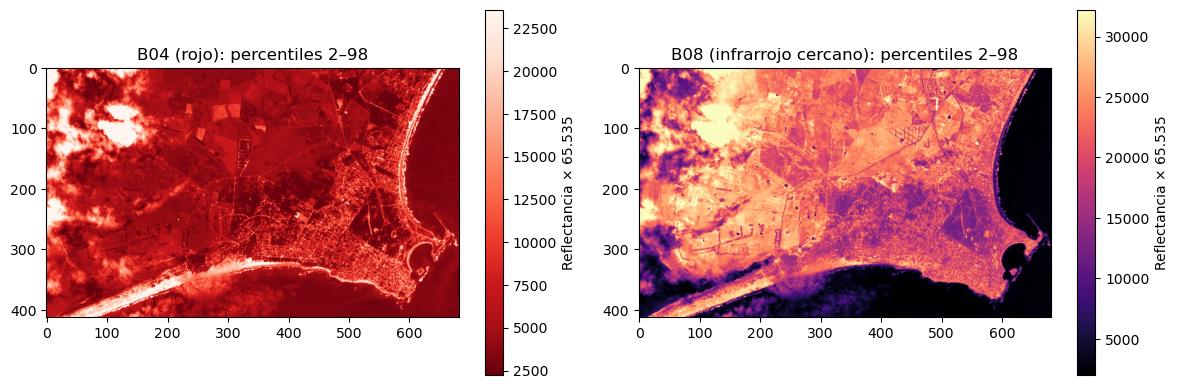

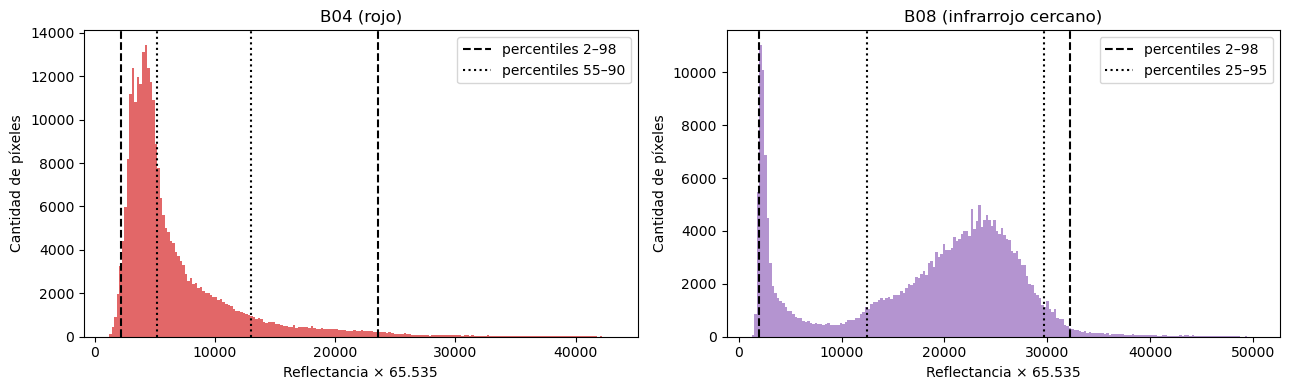

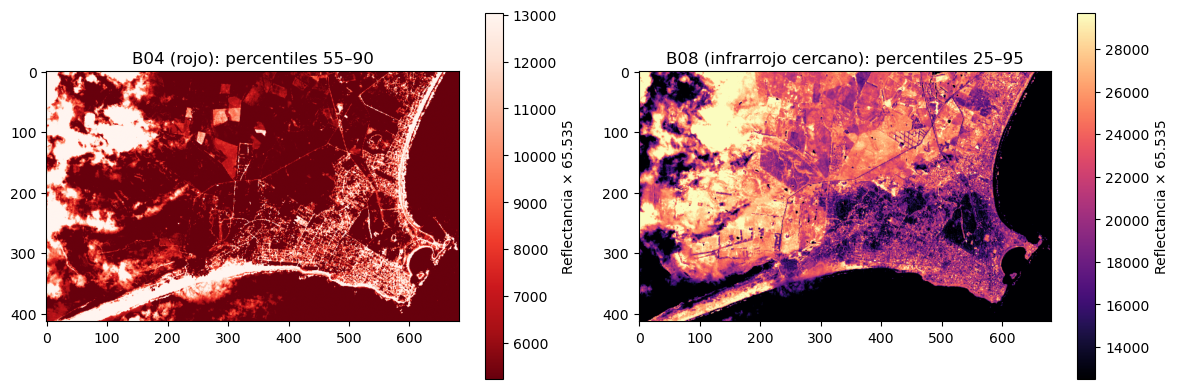

In [26]:
# Estiramiento por percentiles: ejemplo simétrico, histogramas y percentiles elegidos para cada banda
bands = [("B04 (rojo)", B04, "tab:red", "Reds_r"), ("B08 (infrarrojo cercano)", B08, "tab:purple", "magma")]
etiqueta = "Reflectancia × 65.535"

# Percentiles elegidos para cada banda a partir de su histograma
elegidos = {"B04 (rojo)": (55, 90), "B08 (infrarrojo cercano)": (25, 95)}

# 1) Ejemplo simétrico: percentiles 2–98
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, band, _, cmap) in zip(axs, bands):
    lo, hi = np.percentile(band, [2, 98])   # se saturan los píxeles por debajo de lo y por encima de hi
    im = ax.imshow(band, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(f"{name}: percentiles 2–98")
    fig.colorbar(im, ax=ax, label=etiqueta)
plt.tight_layout()
plt.show()

# 2) Histogramas: distribución de valores de cada banda y dónde cortan los percentiles
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, band, color, _) in zip(axs, bands):
    ax.hist(band.ravel(), bins=200, color=color, alpha=0.7)
    for (p_lo, p_hi), style in [((2, 98), "--"), (elegidos[name], ":")]:
        lo, hi = np.percentile(band, [p_lo, p_hi])
        ax.axvline(lo, color="black", linestyle=style, label=f"percentiles {p_lo}–{p_hi}")
        ax.axvline(hi, color="black", linestyle=style)
    ax.set_title(name)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Cantidad de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()

# 3) Percentiles elegidos para cada banda
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, band, _, cmap) in zip(axs, bands):
    p_lo, p_hi = elegidos[name]
    lo, hi = np.percentile(band, [p_lo, p_hi])
    im = ax.imshow(band, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(f"{name}: percentiles {p_lo}–{p_hi}")
    fig.colorbar(im, ax=ax, label=etiqueta)
plt.tight_layout()
plt.show()

#### ¿Qué son las bandas RED y NIR?

En teledetección, **RED** y **NIR** son dos regiones específicas del espectro electromagnético (i.e., de luz) capturadas por sensores en satélites (o drones):

- **Banda Roja (RED)** mide la reflectancia en el espectro de luz roja visible (*longitud de onda de 600–700 nm*; en Sentinel-2, la banda B04 cubre aproximadamente de 650 a 680 nm). La vegetación absorbe la mayor parte de esta luz roja para la fotosíntesis (**valores más bajos**), lo que la convierte en un indicador clave del estado de las plantas. En otras palabras, la cantidad de luz roja reflejada está inversamente relacionada con la cantidad de clorofila en las plantas. El suelo desnudo o las zonas no vegetadas reflejan más luz roja (**valores más altos**). Observá la arena y el agua en las imágenes anteriores: ¿reflejan mucho o poco rojo? ¿Por qué?

- **Banda infrarrojo cercano (NIR)** captura la región de luz que está justo más allá del espectro visible (*longitud de onda de 700–1000 nm*; en Sentinel-2, la banda B08 cubre aproximadamente de 785 a 900 nm). La vegetación sana refleja una gran cantidad de luz NIR por dos motivos: no la usa para la fotosíntesis y, además, la estructura interna de las hojas (las paredes de sus células) la dispersa y la devuelve hacia afuera. Esta alta reflectancia (**valores más altos**) en la banda NIR es característica de la vegetación densa y en buen estado. ¿Hay algún otro componente en la imagen que no hayamos mencionado? ¿Cuál es y cómo se ve en cada banda?

**Espectro electromagnético:**

![Espectro de luz](../images/Light_Spectrum.png)

<details>
<summary><b>Ver respuestas</b> (intentá responder antes de abrir)</summary>

**1. ¿La arena y el agua reflejan mucho o poco rojo?**

- **Arena:** refleja **mucho** rojo. La franja de playa es de lo más claro de la banda roja, junto con las nubes: la arena seca no tiene clorofila que absorba el rojo y refleja bien toda la luz visible. También refleja bastante infrarrojo.
- **Agua:** refleja **poco** rojo. Absorbe gran parte de la luz que le llega, así que en la banda roja se ve oscura y se confunde con la vegetación: las dos quedan juntas en el pico del histograma. En el infrarrojo absorbe casi todo y es lo más oscuro de B08; por eso esa banda sí la separa de la vegetación.

**2. ¿Hay algún otro componente que no mencionamos?**

Sí: las **nubes**, al oeste de la imagen. Son muy brillantes en las dos bandas, porque reflejan casi toda la luz en todas estas longitudes de onda. Por eso fijan el máximo de la escala mínimo–máximo y forman la cola derecha de los histogramas.

</details>


### Paso 4: Cálculo de NDVI

El **NDVI (Normalized Difference Vegetation Index)** es un índice muy usado en teledetección para analizar la cobertura y el estado de la vegetación.

Se define a partir de la reflectancia en la banda **Roja (RED)** y en la banda **Infrarrojo Cercano (NIR)**. En términos simples:

- La vegetación sana absorbe mucha luz roja y refleja bastante NIR.
- Superficies sin vegetación (suelo desnudo, construcciones) tienden a reflejar más rojo y menos NIR.

#### Fórmula

El NDVI se calcula como:

$$\text{NDVI} = \frac{\text{NIR} - \text{RED}}{\text{NIR} + \text{RED}} \qquad\qquad(1)$$

El NDVI siempre da un valor entre -1 y 1. En la práctica, la mayoría de los valores cae en un rango más chico: en esta imagen, el agua da entre -0,3 y -0,06 y la vegetación, entre 0,44 y 0,77.


**Pregunta: ¿Hace falta convertir los valores a reflectancia de cada banda?**

<details>
<summary><b>Ver respuesta</b> (intentá responder antes de abrir)</summary>

No. Los TIFF guardan la reflectancia multiplicada por 65.535 (Paso 3), y ese factor aparece tanto en el numerador como en el denominador, así que se cancela:

$$\frac{65.535\,\text{NIR} - 65.535\,\text{RED}}{65.535\,\text{NIR} + 65.535\,\text{RED}} = \frac{65.535\,(\text{NIR} - \text{RED})}{65.535\,(\text{NIR} + \text{RED})} = \frac{\text{NIR} - \text{RED}}{\text{NIR} + \text{RED}}$$

Por eso podemos usar directamente las bandas `B04` y `B08` tal como las leímos. El NDVI da el mismo valor que con la reflectancia.

</details>



#### Actividades

Con las bandas que ya cargaste y exploraste:

1. **Evitá divisiones por cero:** asegurate de que $\text{NIR} + \text{RED} \neq 0$ antes de aplicar la fórmula.
2. **Calculá el NDVI:** usá arrays de `numpy` para implementar la fórmula (1).
3. **Caracterizá el NDVI:** imprimí valores mínimos, máximos y la forma (`shape`) del array de NDVI.
4. **Visualizá el NDVI:** generá una figura para inspeccionar el patrón espacial del índice.
5. Probá visualizarlo **con** y **sin** fijar la escala usando `vmin=-1, vmax=1`. ¿Qué cambia en la interpretación del mapa?

> Si el mapa te sale todo rojo o todo verde, seguramente no es culpa del satélite: revisá el código antes de putear al hardware.


In [9]:
# Verificar si NIR + RED vale 0 en algún píxel
# .............................
# Solución:
# .............................
sum_nir_red = B08 + B04 # suma de las dos bandas

# .............................
# Solución:
# .............................
zeros_exist = np.any(sum_nir_red == 0) # True si algún valor es 0

print(zeros_exist)

False


- Forma del NDVI: (413, 682)
- NDVI mínimo: -0.43173432
- NDVI máximo: 0.91174155


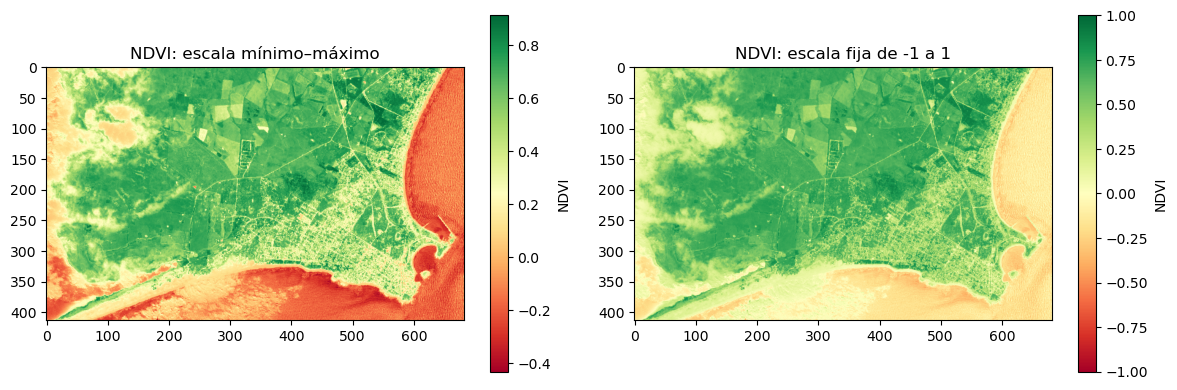

In [10]:
# Calcular y visualizar el NDVI
#.........................
# Solución:
#.........................
ndvi = (B08 - B04) / (B08 + B04)

print('- Forma del NDVI:', ndvi.shape)
print('- NDVI mínimo:', ndvi.min())
print('- NDVI máximo:', ndvi.max())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Sin fijar la escala: mínimo–máximo de esta imagen
im = axs[0].imshow(ndvi, cmap="RdYlGn")
axs[0].set_title("NDVI: escala mínimo–máximo")
fig.colorbar(im, ax=axs[0], label="NDVI")

# Escala fija de -1 a 1: todo el rango posible del NDVI
im = axs[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axs[1].set_title("NDVI: escala fija de -1 a 1")
fig.colorbar(im, ax=axs[1], label="NDVI")

plt.tight_layout()
plt.show()

**Pregunta: ¿Qué cambia en la interpretación del mapa al fijar la escala?**

<details>
<summary><b>Ver respuesta</b> (intentá responder antes de abrir)</summary>

- **Sin fijar la escala (mínimo–máximo):** los colores van del mínimo de esta imagen (≈ −0,43) a su máximo (≈ 0,91). El amarillo, que es el centro del mapa de colores, cae en ≈ 0,24 y no en 0. Por eso el agua, con un NDVI apenas negativo (entre −0,3 y −0,06), aparece en rojo intenso, como si fuera muy distinta del resto, y dentro de la vegetación se ven muchos matices.
- **Escala fija de −1 a 1:** el amarillo cae en 0, el límite entre las superficies que reflejan más rojo que infrarrojo (NDVI negativo) y las que reflejan más infrarrojo que rojo (NDVI positivo). El agua se ve naranja claro, porque su NDVI está cerca de 0, y la vegetación (NDVI entre 0,44 y 0,77) en verde.

Con la escala fija, un color indica siempre el mismo valor de NDVI, así que se pueden comparar mapas de distintas fechas o lugares. Con mínimo–máximo, en cambio, los colores dependen de los extremos de cada imagen: sirve para ver detalles dentro de una sola imagen, pero no para comparar imágenes. Es lo mismo que vimos con las bandas en el Paso 3.

</details>


#### Nota sobre métricas e interpretación (para más adelante)

Más adelante en el notebook vas a trabajar con series temporales de NDVI (varios años). Allí vas a:

- Calcular diferentes métricas para cada imagen (media, mediana, porcentaje de alta vegetación, etc.).
- Compilar esas métricas en un pequeño conjunto de datos.
- Representar la evolución en el tiempo con un gráfico de líneas (eje X: años, eje Y: métricas de NDVI).

Las preguntas clave serán cosas como:

- ¿Cómo cambió la vegetación entre 2016 y 2024?
- ¿Se ve recuperación, degradación o patrones estacionales?
- ¿Qué dicen las métricas sobre el “estado de salud” del área?

> Podés saltearte esta nota por ahora y volver cuando llegues a la parte de series temporales. No hace falta adelantarse… salvo que seas de esas personas que leen el final del libro primero.


## Paso 5: Índices adicionales

Además del NDVI, se pueden construir otros índices a partir de combinaciones de distintas bandas. Uno muy usado para monitorizar cuerpos de agua es el **NDWI (Normalized Difference Water Index)**.

El NDWI busca resaltar zonas con agua y atenuar la presencia de vegetación y suelo. Se calcula usando la banda **Verde (B03 - 559 nm)** y la banda **NIR (B08)**:

$$\text{NDWI} = \frac{\text{Green} - \text{NIR}}{\text{Green} + \text{NIR}} \qquad\qquad(2)$$

En esta fórmula, el agua suele tener:
- Baja reflectancia en NIR (B08).
- Mayor reflectancia en la banda verde (B03).

Los valores de NDWI también van, en teoría, de -1 a 1. Valores positivos tienden a indicar presencia de agua; valores negativos suelen corresponder a suelo, vegetación o áreas urbanas.

**4 ejercicios:**

1. Descargá las bandas **B03** y **B08** (Raw, como en el Paso 2) para monitorear el agua de algún reservorio o embalse del mundo (como ejemplo, yo te adjunto las del Pantà de la Llosa del Cavall, en Sant Llorenç de Morunys, España, en `raw/ndwi/`). Elegí (al menos) dos fechas en las que sea razonable esperar una diferencia notable en el nivel del agua, como una imagen de invierno y otra de verano. Si usás tus imágenes, guardalas en una carpeta propia (`raw/ndwi_mio/`) y cambiá `directory_path` en el código.

2. Inicializá un diccionario llamado `bandas`, reutilizá la función `read_band` (Paso 3) para leer cada banda y completá el código para imprimir la forma (`shape`), el mínimo, el máximo y la mediana de cada banda de ambos años.

In [ ]:
directory_path = Path('../raw/ndwi')
# Cargar las bandas B03 y B08 de cada fecha
# .............................
# Solución:
# .............................
bandas = {}   # {fecha: {"B03": array, "B08": array}}

for file_path in sorted(directory_path.glob("*_(Raw).tiff")):
    fecha = re.search(r"\d{4}-\d{2}-\d{2}", file_path.name).group()
    banda = re.search(r"B\d{2}", file_path.name).group()

    # .............................
    # Solución:
    # .............................
    data, meta = read_band(file_path)

    bandas.setdefault(fecha, {})[banda] = data

    print(file_path.name)
    # .............................
    # Solución:
    # .............................
    print(f' - Forma: {data.shape} | Tipo original: {meta["dtype"]} | CRS: {meta["crs"]}')
    print(f' - Mínimo: {data.min():.0f} | Máximo: {data.max():.0f} | Mediana: {np.median(data):.0f}'
          f' (reflectancia ≈ {np.median(data) / 65535:.2f})')
    print('')

2017-04-06-00_00_2017-04-06-23_59_Sentinel-2_L2A_B03_(Raw).tiff
 - Forma: (446, 702) | Tipo original: uint16 | CRS: EPSG:4326
 - Mínimo: 0 | Máximo: 44642 | Mediana: 2608 (reflectancia ≈ 0.04)

2017-04-06-00_00_2017-04-06-23_59_Sentinel-2_L2A_B08_(Raw).tiff
 - Forma: (446, 702) | Tipo original: uint16 | CRS: EPSG:4326
 - Mínimo: 0 | Máximo: 55259 | Mediana: 12969 (reflectancia ≈ 0.20)

2024-08-04-00_00_2024-08-04-23_59_Sentinel-2_L2A_B03_(Raw).tiff
 - Forma: (446, 702) | Tipo original: uint16 | CRS: EPSG:4326
 - Mínimo: 0 | Máximo: 65535 | Mediana: 3722 (reflectancia ≈ 0.06)

2024-08-04-00_00_2024-08-04-23_59_Sentinel-2_L2A_B08_(Raw).tiff
 - Forma: (446, 702) | Tipo original: uint16 | CRS: EPSG:4326
 - Mínimo: 0 | Máximo: 65535 | Mediana: 17209 (reflectancia ≈ 0.26)




3. Calculá el NDWI de cada fecha con la fórmula (2) (como en el Paso 4, cuidá las divisiones por cero) y mostrá en una grilla de 3 filas y 2 columnas las bandas B03 y B08 y el NDWI, con una columna por fecha. Usá un mapa de colores apropiado para cada fila (por ejemplo, `'Greens_r'`, `'magma'` y `'RdBu'` o `'coolwarm'`) y la misma escala en las dos fechas, para poder compararlas. La escala común de cada banda ya está calculada en el diccionario `escalas`.

4.	Compará visualmente los NDWI de ambas fechas e identificá las diferencias en el estado del embalse.

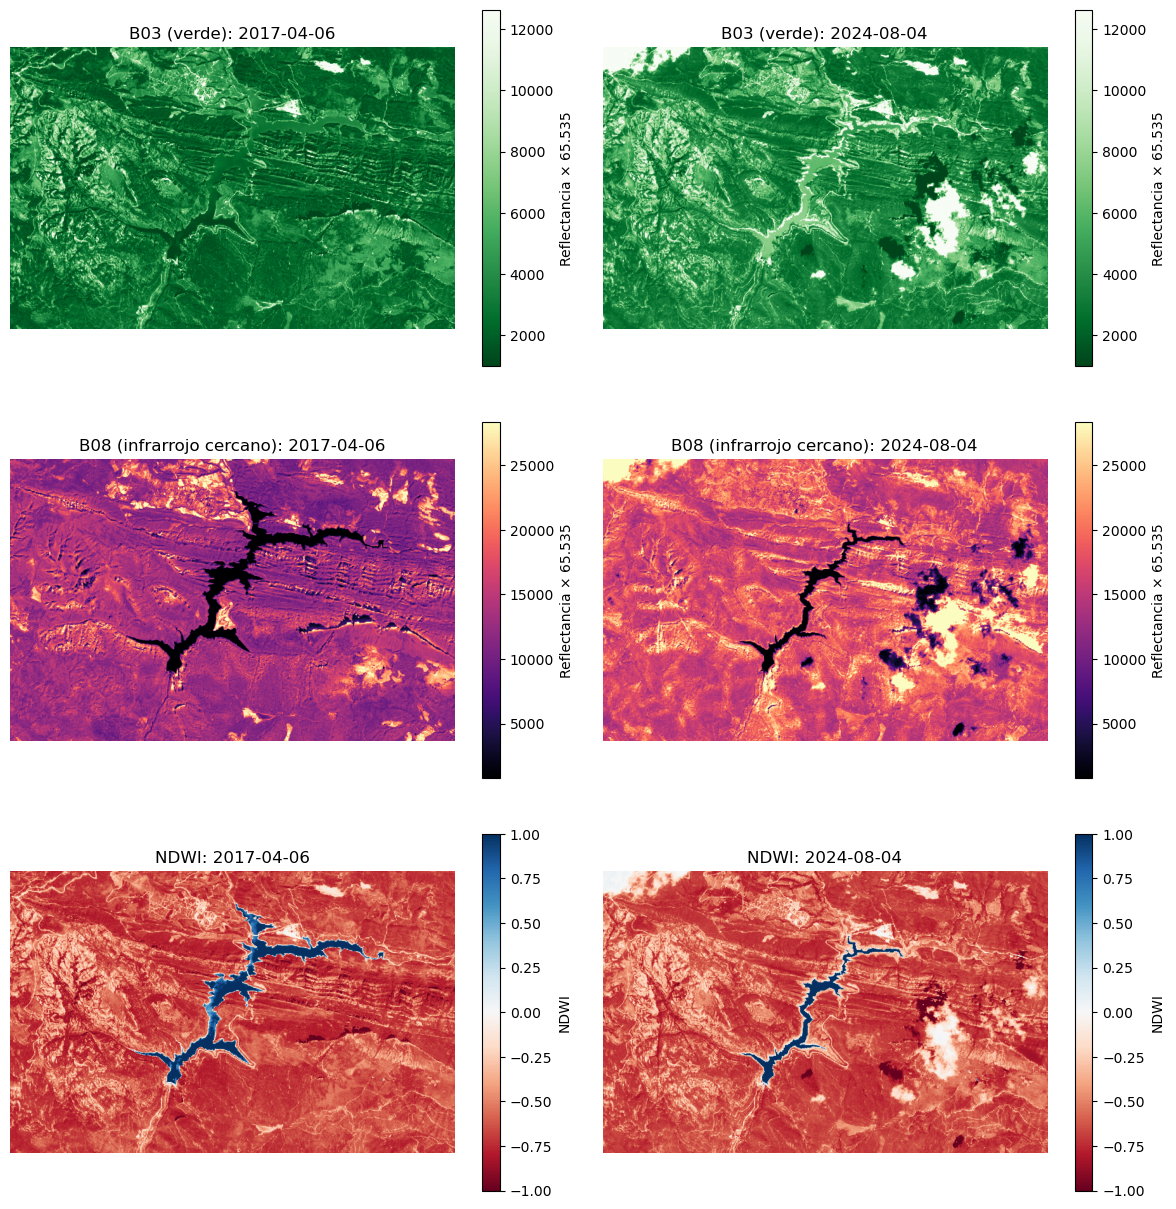

In [ ]:
# B03, B08 y NDWI de cada fecha: una columna por fecha
fechas = sorted(bandas)

# Escala común a las dos fechas para cada banda: percentiles 2–98 de todos sus píxeles
escalas = {}
for banda in ["B03", "B08"]:
    valores = np.concatenate([bandas[f][banda].ravel() for f in fechas])
    escalas[banda] = np.percentile(valores, [2, 98])

fig, axs = plt.subplots(3, 2, figsize=(12, 13))

for col, fecha in enumerate(fechas):
    # .............................
    # Solución:
    # .............................
    B03, B08 = bandas[fecha]["B03"], bandas[fecha]["B08"]
    suma = B03 + B08
    ndwi = np.divide(B03 - B08, suma, out=np.full_like(suma, np.nan), where=suma > 0)   # NaN donde B03 + B08 = 0


    filas = [
        (B03, "B03 (verde)", "Greens_r", *escalas["B03"]),
        (B08, "B08 (infrarrojo cercano)", "magma", *escalas["B08"]),
        (ndwi, "NDWI", "RdBu", -1, 1),   # rango posible del NDWI; azul: agua (NDWI > 0)
    ]
    for fila, (img, nombre, cmap, vmin, vmax) in enumerate(filas):
        ax = axs[fila, col]
        im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)   # misma escala en las dos fechas
        ax.set_title(f"{nombre}: {fecha}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, label="NDWI" if nombre == "NDWI" else "Reflectancia × 65.535", shrink=0.8)

plt.tight_layout()
plt.show()

### Paso 6: Operaciones sobre imágenes

#### Umbralización (thresholding) de NDWI para aislar cuerpos de agua

Con el NDWI calculado, podés identificar píxeles que corresponden a agua aplicando un **umbral (threshold)**.

1. Usá código similar al provisto para entender cómo funcionan las **máscaras booleanas**. Por ejemplo, si tenés un array `[0.15, 0.05, 0.30, 0.20]` y elegís `threshold = 0.15`, la comparación `array > threshold` da `[False, False, True, True]`.

[False False False False False False False  True  True False  True  True]


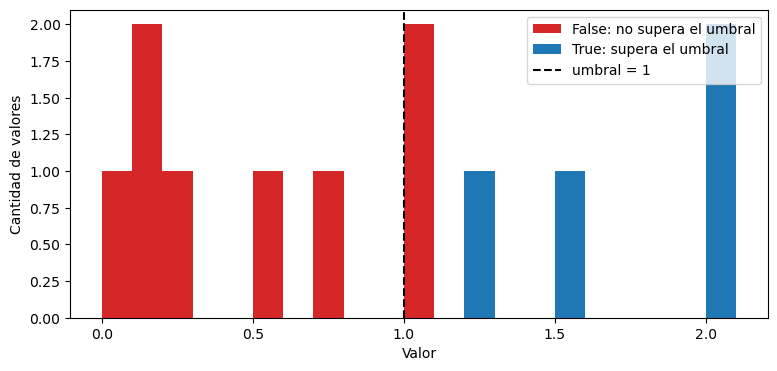

In [58]:
some_array = np.array([0.05, 0.15, 0.15, 0.20, 0.5, 0.75, 1, 1, 1.25, 1.5, 2, 2])
# .............................
# Solución:
# .............................
my_threshold = 1
masked_array = some_array > my_threshold   # True donde el valor supera el umbral
print(masked_array)

# Histograma: la máscara separa los valores a cada lado del umbral
bins = np.arange(0, 2.2, 0.1)   # intervalos de 0,1
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(some_array[~masked_array], bins=bins, color="tab:red", label="False: no supera el umbral")
ax.hist(some_array[masked_array], bins=bins, color="tab:blue", label="True: supera el umbral")
ax.axvline(my_threshold, color="black", linestyle="--", label=f"umbral = {my_threshold}")
ax.set_xlabel("Valor")
ax.set_ylabel("Cantidad de valores")
ax.legend()
plt.show()

2. Implementá una función que, dado un NDWI y un umbral, devuelva una máscara binaria (agua / no agua).

In [37]:
def apply_mask(data, threshold=0):
    """
    Crea una máscara de agua a partir del NDWI.
    - Parámetros:
        data (numpy.ndarray): NDWI de una fecha.
        threshold (float): valor de NDWI por encima del cual un píxel se considera agua.
    - Devuelve:
        numpy.ndarray de booleanos: True (agua) donde data > threshold.
    """
    # .............................
    # Solución:
    # .............................
    return data > threshold   # los píxeles NaN dan False

3. Analizá el rango de valores de NDWI (mínimo, máximo, histograma). El **histograma** es una excelente herramienta para ajustar el umbral: muestra cómo se reparten los valores de los píxeles de tierra y de agua, y dónde conviene cortar para separarlos.
4. Visualizá cómo cambia la imagen al aplicar la máscara, en una grilla de 3x2: en la fila 1, el NDWI de las fechas 1 y 2; en las filas 2 y 3, el NDWI enmascarado con cada umbral. Tenés **dos umbrales para jugar** (`umbral_1` y `umbral_2`): cambialos y observá qué píxeles entran o salen de la máscara.

Preguntas clave:

- ¿Qué pasa cuando bajás o subís el valor del umbral?
- ¿Aparecen zonas mal clasificadas (por ejemplo, áreas que no son agua pero entran como “agua”)?
- Según el histograma, ¿dónde conviene ubicar el umbral? ¿Sirve el mismo umbral para las dos fechas?
- ¿Por qué hay picos justo en -1 y en 1?

> Spoiler: elegir el umbral “perfecto” es más arte que ciencia. Pero no lo digas en voz alta delante de alguien que hace clasificación supervisada.


2017-04-06: NDWI mínimo = -1.00 | máximo = 1.00
2024-08-04: NDWI mínimo = -1.00 | máximo = 1.00


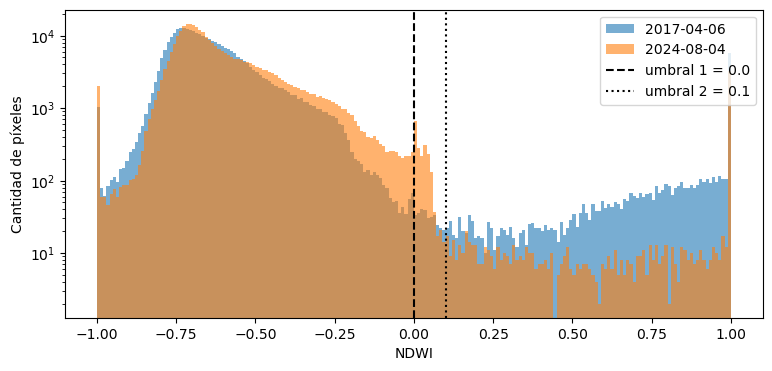

2017-04-06, NDWI > 0.0: 10273 píxeles de agua (3.3% de la imagen)
2017-04-06, NDWI > 0.1: 9965 píxeles de agua (3.2% de la imagen)
2024-08-04, NDWI > 0.0: 5546 píxeles de agua (1.8% de la imagen)
2024-08-04, NDWI > 0.1: 4027 píxeles de agua (1.3% de la imagen)


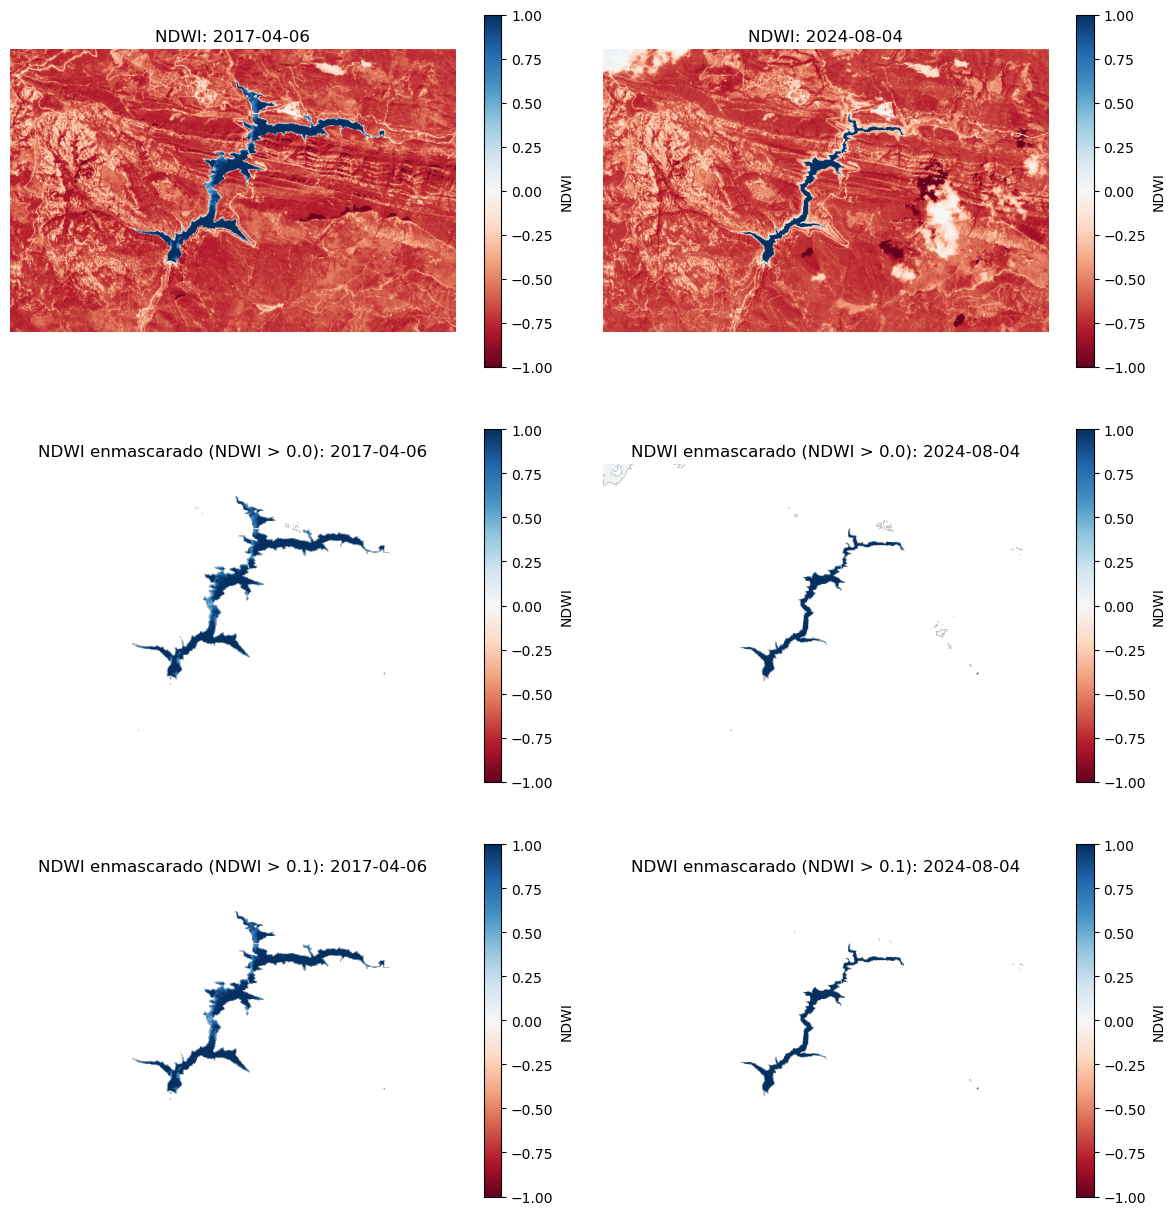

In [63]:
# NDWI de cada fecha, histogramas y posibles máscaras de agua (NDWI > umbral: agua)
# .............................
# Solución:
# .............................
umbral_1 = 0.0
umbral_2 = 0.1

ndwi = {}
for fecha in fechas:
    B03, B08 = bandas[fecha]["B03"], bandas[fecha]["B08"]
    suma = B03 + B08
    ndwi[fecha] = np.divide(B03 - B08, suma, out=np.full_like(suma, np.nan), where=suma > 0)
    print(f"{fecha}: NDWI mínimo = {np.nanmin(ndwi[fecha]):.2f} | máximo = {np.nanmax(ndwi[fecha]):.2f}")

# 1) Histogramas del NDWI (eje vertical logarítmico: hay muchos menos píxeles de agua que de tierra)
fig, ax = plt.subplots(figsize=(9, 4))
for fecha in fechas:
    valores = ndwi[fecha][~np.isnan(ndwi[fecha])]   # sin los NaN
    ax.hist(valores, bins=200, alpha=0.6, label=fecha)
ax.axvline(umbral_1, color="black", linestyle="--", label=f"umbral 1 = {umbral_1}")
ax.axvline(umbral_2, color="black", linestyle=":", label=f"umbral 2 = {umbral_2}")
ax.set_yscale("log")
ax.set_xlabel("NDWI")
ax.set_ylabel("Cantidad de píxeles")
ax.legend()
plt.show()

# 2) Grilla 3x2: NDWI (fila 1) y NDWI enmascarado con cada umbral, solo el agua (filas 2 y 3)
fig, axs = plt.subplots(3, 2, figsize=(12, 13))
for col, fecha in enumerate(fechas):
    im = axs[0, col].imshow(ndwi[fecha], cmap="RdBu", vmin=-1, vmax=1)
    axs[0, col].set_title(f"NDWI: {fecha}")
    fig.colorbar(im, ax=axs[0, col], label="NDWI", shrink=0.8)

    for fila, umbral in enumerate([umbral_1, umbral_2], start=1):
        agua = apply_mask(ndwi[fecha], umbral)
        print(f"{fecha}, NDWI > {umbral}: {agua.sum()} píxeles de agua ({agua.mean():.1%} de la imagen)")

        im = axs[fila, col].imshow(np.where(agua, ndwi[fecha], np.nan), cmap="RdBu", vmin=-1, vmax=1)   # NaN: no se dibuja
        axs[fila, col].set_title(f"NDWI enmascarado (NDWI > {umbral}): {fecha}")
        fig.colorbar(im, ax=axs[fila, col], label="NDWI", shrink=0.8)

for ax in axs.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

<details>
<summary><b>Ver respuestas</b> (intentá responder antes de abrir)</summary>

**1. ¿Qué pasa cuando bajás o subís el valor del umbral?**

Al **subir** el umbral la máscara se achica: solo quedan los píxeles con NDWI más alto. Al **bajarlo** se agranda y entran píxeles con NDWI cercano a 0. Pero el embalse casi no se entera: el 95 % de sus píxeles tiene un NDWI de unos 0,3 o más, y más de la mitad vale 1, lejos de los dos umbrales. Lo que cambia son los bordes:

- **2017:** pasar de 0 a 0,1 quita 308 píxeles (el 3 % de la máscara). Dos tercios están en la orilla del embalse: son **píxeles mixtos**, que mezclan agua y tierra dentro de los 15 m × 15 m del píxel.
- **2024:** el mismo cambio quita 1.519 píxeles (el 27 % de la máscara), y casi todos (1.346) son **bordes de nubes**.

Si bajás el umbral por debajo de 0 (por ejemplo, a -0,1), entran todavía más píxeles que no son agua: en 2024, unos 2.800 más, casi todos de nubes.

**2. ¿Aparecen zonas mal clasificadas?**

Sí, sobre todo en 2024:

- **Nubes:** reflejan mucho y parecido en el verde y en el infrarrojo, así que su NDWI queda cerca de 0. Con el umbral en 0, sus bordes entran como "agua". Se ven arriba a la izquierda y a la derecha de la imagen, sobre las nubes.
- **Orillas:** los píxeles mixtos tienen un NDWI intermedio y entran o salen de la máscara según el umbral. Esto no es un error del índice, sino de la resolución: el borde real del agua pasa por adentro del píxel.
- **Manchas sueltas:** quedan algunas manchas chicas, de pocos píxeles, lejos del embalse. Pueden ser pequeñas lagunas o ruido; con esta resolución no se puede asegurar.

Las **sombras** de las nubes, en cambio, en general no se confunden con agua: son oscuras en las dos bandas, pero sobre todo en el verde, y su NDWI es muy negativo.

**3. ¿Dónde conviene ubicar el umbral? ¿Sirve el mismo para las dos fechas?**

El histograma muestra dos grupos: un pico grande alrededor de -0,7 (la tierra) y una cola de valores altos (el agua). Entre los dos, aproximadamente de 0 a 0,3, hay muy pocos píxeles: cualquier umbral en ese **valle** separa casi igual el embalse. La diferencia entre las fechas está en las nubes: en 2024 forman una pequeña joroba justo alrededor de 0, que no aparece en 2017. Por eso 0,1 funciona bien en las dos fechas, y 0 funciona en 2017 pero no en 2024: **el umbral depende de cada imagen**, y conviene revisarlo con su histograma. Para comparar fechas, lo ideal es un **mismo umbral** que caiga en el valle de todas: así el cambio medido se debe al embalse y no a haber cambiado el criterio. Si las imágenes son muy distintas (agua turbia, otra estación, neblina), puede hacer falta uno por fecha.

> Existen métodos que eligen el umbral automáticamente a partir del histograma, como el **método de Otsu**, que busca el corte que mejor separa los dos grupos.

**4. ¿Por qué hay picos justo en -1 y en 1?**

Son píxeles en los que **una de las dos bandas vale 0**:

- **NDWI = 1:** el infrarrojo (B08) vale 0. Pasa en el agua profunda, que absorbe casi todo el infrarrojo. Son más de la mitad de los píxeles del embalse.
- **NDWI = -1:** el verde (B03) vale 0. Pasa en algunos píxeles muy oscuros, como las sombras.

Si B08 = 0, la fórmula da $\frac{B03 - 0}{B03 + 0} = 1$; y si B03 = 0, da $\frac{0 - B08}{0 + B08} = -1$. Por eso esos píxeles se acumulan en los extremos exactos del rango.

</details>


#### Sustracción de imágenes para detección de cambios

En teledetección, comparar imágenes de distintos momentos es una forma poderosa de detectar cambios a lo largo del tiempo y cuantificar la magnitud de dichos cambios (e.g., en lagos, embalses u otras superficies de agua, vegetación, etc.).

Si tenés NDWI para dos fechas (por ejemplo, un año húmedo y un año seco), podés restar:

$$\text{Cambio} = \text{NDWI}{(\text{fecha tardía})} - \text{NDWI}{(\text{fecha temprana})}$$

- Valores **positivos** indican un aumento en el NDWI (posible incremento en agua).
- Valores **negativos** indican disminución (posible retracción del cuerpo de agua).

La imagen resultante resalta las zonas donde cambió el NDWI. Para medir cuánto se redujo o expandió el embalse, conviene comparar también las **máscaras de agua** de las dos fechas.

**Ejercicios:**

1. Elegí un umbral a partir del análisis anterior (histogramas y máscaras) y guardalo en la variable `umbral_elegido`.
2. Calculá el cambio de NDWI entre las dos fechas y mostralo con un mapa de colores divergente (por ejemplo, `'RdBu'`) y una escala simétrica, de -2 a 2: el rango posible de una resta de NDWI. ¿Qué pasa si desactivás la escala?
3. Restá las máscaras de agua de las dos fechas, convertidas a números enteros (`True` = 1, `False` = 0), y mostrá el resultado: -1 es agua perdida, 0 es sin cambio y +1 es agua nueva.
4. Interpretá la superficie de agua de cada fecha en hectáreas. El tamaño del píxel está en grados (EPSG:4326, en `meta["transform"]`): para pasarlo a metros, 1° de latitud ≈ 110,5 km y 1° de longitud ≈ 111,3 km × cos(latitud).

**Preguntas:**

- ¿Todas las zonas azules del mapa de cambio de NDWI son agua nueva? ¿Qué otra cosa puede hacer subir el NDWI?
- ¿Qué muestra la resta de las máscaras que no muestra el mapa de cambio de NDWI? ¿Y al revés?
- ¿Cuánto se redujo el embalse entre las dos fechas? ¿Cuánto confiarías en ese número?

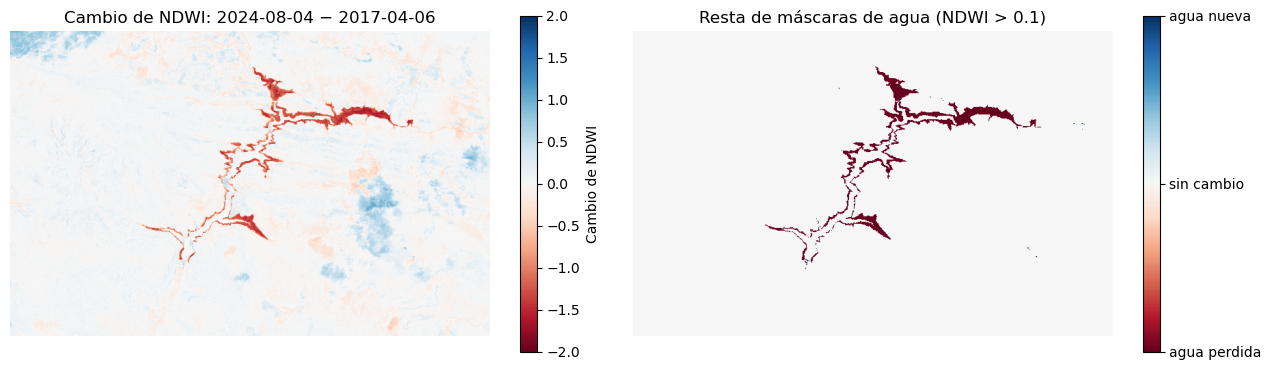

Superficie de un píxel: 219 m²
Agua el 2017-04-06: 218 ha
Agua el 2024-08-04: 88 ha
Agua perdida: 131 ha | agua nueva: 1 ha


In [ ]:
# Cambio entre fechas: NDWI y máscaras de agua
# .............................
# Solución:
# .............................
# 1. Umbral elegido a partir del análisis anterior: 0,1 cae en el valle del histograma y 
# deja afuera los bordes de las nubes
umbral_elegido = 0.1

temprana, tardia = fechas
# .............................
# Solución:
# .............................
# 2. Cambio de NDWI entre las dos fechas
cambio = ndwi[tardia] - ndwi[temprana]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
im = axs[0].imshow(cambio, cmap="RdBu", vmin=-2, vmax=2)   # rango posible de una resta de NDWI
axs[0].set_title(f"Cambio de NDWI: {tardia} − {temprana}")
fig.colorbar(im, ax=axs[0], label="Cambio de NDWI", shrink=0.8)

# .............................
# Solución:
# .............................
# 3. Restar las máscaras (True = 1, False = 0)
agua_temprana = apply_mask(ndwi[temprana], umbral_elegido)
agua_tardia = apply_mask(ndwi[tardia], umbral_elegido)
cambio_agua = agua_tardia.astype(int) - agua_temprana.astype(int)   # -1: agua perdida, 0: sin cambio, +1: agua nueva

im = axs[1].imshow(cambio_agua, cmap="RdBu", vmin=-1, vmax=1)
axs[1].set_title(f"Resta de máscaras de agua (NDWI > {umbral_elegido})")
cbar = fig.colorbar(im, ax=axs[1], ticks=[-1, 0, 1], shrink=0.8)
cbar.ax.set_yticklabels(["agua perdida", "sin cambio", "agua nueva"])
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4. Superficie: el tamaño del píxel está en grados (EPSG:4326).
# 1° de latitud ≈ 110,5 km y 1° de longitud ≈ 111,3 km × cos(latitud)
t = meta["transform"]
latitud = t.f + t.e * meta["height"] / 2   # latitud del centro de la imagen
ha_pixel = (t.a * 111_320 * np.cos(np.radians(latitud))) * (-t.e * 110_540) / 10_000

print(f"Superficie de un píxel: {ha_pixel * 10_000:.0f} m²")
print(f"Agua el {temprana}: {agua_temprana.sum() * ha_pixel:.0f} ha")
print(f"Agua el {tardia}: {agua_tardia.sum() * ha_pixel:.0f} ha")
print(f"Agua perdida: {(cambio_agua == -1).sum() * ha_pixel:.0f} ha | agua nueva: {(cambio_agua == 1).sum() * ha_pixel:.0f} ha")

<details>
<summary><b>Ver respuestas</b> (intentá responder antes de abrir)</summary>

**1. ¿Todas las zonas azules del mapa de cambio son agua nueva?**

No. Las manchas azules grandes, a la derecha y arriba a la izquierda de la imagen, son las **nubes** de 2024. El NDWI de una nube queda cerca de 0, mientras que el de la tierra que tapan ronda -0,7: la resta da un aumento de entre 0,5 y 0,8, aunque no haya ni una gota de agua nueva. De los píxeles cuyo NDWI sube más de 0,5, el 96 % son nubes. En cambio, donde el embalse se retiró el NDWI baja mucho (alrededor de -1,2, en rojo), y en la tierra sin nubes casi no cambia (cerca de 0).

Por eso el mapa de cambio de NDWI sirve para ver **dónde** cambió algo, pero no alcanza para decir **qué** cambió: hay que interpretarlo junto con las imágenes de cada fecha.

**¿Y si desactivás la escala?** Sin `vmin` ni `vmax`, la escala va del mínimo (-1,69) al máximo (+1,23) del cambio, y el blanco, el centro del mapa de colores, cae en -0,23 en lugar de 0. El 76 % de los píxeles casi no cambia (menos de 0,1), pero queda **celeste**, y toda la imagen parece un aumento de agua. Con la escala simétrica, de -2 a 2, el blanco queda en 0 y significa "sin cambio": es lo mismo que vimos con el NDVI en el Paso 4.

**2. ¿Qué muestra la resta de las máscaras que no muestra el mapa de cambio de NDWI? ¿Y al revés?**

- **La resta de las máscaras** responde directamente dónde hay agua perdida o nueva: cada píxel vale -1, 0 o +1. Las nubes no aparecen como agua nueva, porque su NDWI no supera el umbral en ninguna de las dos fechas. Y como cada píxel es agua o no, se puede contar la superficie en hectáreas.
- **El mapa de cambio de NDWI** muestra cuánto cambió cada píxel, también fuera del agua: ahí se ven las nubes y los cambios en la tierra. Pero no dice qué es agua y qué no.

La máscara **simplifica** (decide agua sí o no) y por eso sirve para medir; el NDWI **conserva el detalle** y por eso sirve para interpretar. Se usan juntos.

**3. ¿Cuánto se redujo el embalse? ¿Cuánto confiarías en ese número?**

Con un umbral de 0,1, el agua pasa de unas **218 ha** el 6/4/2017 a unas **88 ha** el 4/8/2024: el embalse perdió alrededor del **60 %** de su superficie (131 ha de agua perdida y solo 1 ha nueva).

Es una buena estimación, pero no exacta:

- **Depende del umbral:** con 0, en lugar de 0,1, da 225 ha y 121 ha, porque en 2024 entran los bordes de las nubes.
- **Píxeles mixtos:** cada píxel mide unos 15 m × 15 m (≈ 220 m²), y en la orilla mezcla agua y tierra. Con un embalse angosto, como el de 2024, la orilla pesa mucho en el total.
- **Conversión de grados a metros:** es aproximada, y usa la latitud del centro de la imagen.
- **Solo dos fechas:** una de primavera y otra de verano. Muestran cuánto cambió el embalse entre esos dos días, pero no alcanzan para saber si es una tendencia o una variación de la temporada.

</details>


### Paso 7: Análisis de NDVI para múltiples archivos (serie temporal)

En esta última parte vas a trabajar con **varias imágenes** de NDVI correspondientes a distintos años (por ejemplo, yo elegí mi barrio entre 2016–2024) para estudiar la evolución de la vegetación.

1. Empezá con una sola imagen:
    - Abrí y visualizá el **NDVI** de un archivo.
    - Ajustá los valores al intervalo [-1, 1], mapeando correctamente el rango disponible.
    - Mostrá la imagen de NDVI “cruda” y la normalizada lado a lado.
    - Calculá algunas métricas:
        - **NDVI medio (mean):** nivel promedio de vegetación.
        - **NDVI mediano (median):** más robusto frente a valores extremos.
        - **Porcentaje de alta vegetación:** proporción de píxeles con NDVI por encima de un cierto umbral (e.g., NDVI > 0.6).

2. Visualiza el NDVI a lo largo de los años:
    - Representá en una grilla de 3x3 el NDVI para cada año. Usa un colormap consistente escalado (-1 y 1, por ejemplo) para una comparación consistente.

3. Extendé el análisis hecho en 1. a todos los años disponibles:
    - Repetí el cálculo de métricas para cada imagen de NDVI.
    - Guardá estas métricas en una estructura tipo tabla (por ejemplo, un `DataFrame`).
    - Creá un gráfico de líneas donde:
        - Eje X: años.
        - Eje Y: métricas de NDVI (media, mediana, porcentaje de alta vegetación).
    - Analizá las tendencias temporales en la salud de la vegetación.

3. Preguntas clave:
    - ¿Cómo evolucionó la vegetación?
    - ¿Se observan tendencias claras (recuperación, degradación, estacionalidad)?
    - ¿Qué cuentan las métricas sobre el estado general del área?

> Si llegaste hasta acá sin que se rompa nada, podés premiarte con un mate o algo rico: ya estás haciendo análisis de series temporales con imágenes satelitales como si nada.


In [ ]:
# Mask to copmute only pixel above the threshold:
# Understand this technique:
ndvi_real = np.array([[0.15, 0.05, 0.30, 0.20],
                      [0.10, 0.35, 0.20, 0.20]])
print('Array:\n', ndvi_real)
mask = ##COMPLETE THE CODE HERE##
print('Mask:\n', mask)
filtered_values = ndvi_real[mask]
print('Filtered values:', filtered_values)
print('Filtered values sum:', filtered_values.sum())
print('Filtered values mean:', filtered_values.mean())

In [ ]:
# Function to normalize NDVI
def normalize_ndvi(ndvi_raw):
    return -(ndvi_raw - ndvi_raw.max() / 2) / (ndvi_raw.max() / 2)

# Function to calculate NDVI metrics
def calculate_metrics(ndvi_normalized, thresholds=[0.5, 0.6, 0.7]):
    mean_ndvi = ndvi_normalized.mean()
    median_ndvi = np.median(ndvi_normalized)
    high_veg_percentages = [
        (ndvi_normalized > threshold).sum() / ndvi_normalized.size * 100
        for threshold in thresholds
    ]
    return mean_ndvi, median_ndvi, high_veg_percentages

In [ ]:
# Root directory
directory_path = Path('raw/time_series_1')

for i, file_path in enumerate(sorted(directory_path.glob("*2024*.tiff"))):
    ndvi_raw, _ = read_band(file_path)

    print(f"Image Shape: {file_path.name}")
    print(f"Data Shape: {ndvi_raw.shape}")
    print(f"Scope: Min = {ndvi_raw.min()}, Max = {ndvi_raw.max()}\n")

    ndvi_normalized = normalize_ndvi(ndvi_raw)
    print(f"Normalized Data Shape: {ndvi_normalized.shape}")
    print(f"Scope: Min = {ndvi_normalized.min()}, Max = {ndvi_normalized.max()}")

    # Calculate metrics for this image
    thresholds=[0.4, 0.6, 0.7]
    mean_ndvi, median_ndvi, high_veg = calculate_metrics(ndvi_normalized, thresholds)

    # Print metrics
    print(f"Mean NDVI: {mean_ndvi:.4f}")
    print(f"Median NDVI: {median_ndvi:.4f}")
    print(f"High Vegetation Percentage (NDVI > {thresholds[0]}): {high_veg[0]:.2f}%")
    print(f"High Vegetation Percentage (NDVI > {thresholds[1]}): {high_veg[1]:.2f}%")
    print(f"High Vegetation Percentage (NDVI > {thresholds[2]}): {high_veg[2]:.2f}%")

    # Plot both images side by side
    plt.figure(figsize=(12, 4))

    # Plot raw NDVI
    plt.subplot(1, 2, 1)
    plt.title("Raw NDVI")
    plt.imshow(ndvi_raw, cmap='RdYlGn')
    plt.colorbar(label='Raw NDVI Value')
    plt.axis('off')

    # Plot normalized NDVI
    plt.subplot(1, 2, 2)
    plt.title("Normalized NDVI (-1 to 1)")
    plt.imshow(ndvi_normalized, cmap='RdYlGn')
    plt.colorbar(label='Normalized NDVI Value')
    plt.axis('off')

    # Display the plots
    plt.tight_layout()
    plt.show()

### Extra:

Análisis equivalente para el Delta del Paraná, Buenos Aires, Argentina entre 2016 y 2024.

In [ ]:
# Variables to store NDVI mean values
ndvi_means = []
ndvi_means_vegetation = {threshold: [] for threshold in [0.1, 0.3, 0.6]}  # NDVI vegetation means by threshold
years = []

# Configure the 3x3 grid for plotting NDVI images
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# Process all .tiff files in the directory
for i, file_path in enumerate(sorted(directory_path.glob("*.tiff"))):
    # Extract the year from the filename
    year = int(re.search(r"(\d{4})", file_path.name).group(1))
    years.append(year)
    
    # Open NDVI file
    band, _ = read_band(file_path)
    # Descale NDVI
    ndvi_real = (32768 - band) / 32768
    ndvi_real = normalize_ndvi(band)
    # Calculate overall NDVI mean
    ndvi_means.append(ndvi_real.mean())
    # Calculate NDVI means for vegetation thresholds
    for threshold in ndvi_means_vegetation.keys():
        mask = ndvi_real > threshold
        ndvi_means_vegetation[threshold].append(ndvi_real[mask].mean())

    # Plot each NDVI image in the 3x3 grid
    ax = axes[i]
    im = ax.imshow(ndvi_real, cmap='RdYlGn', vmin=-1, vmax=1)
    ax.set_title(f"Year: {year}", fontsize=10)
    ax.axis('off')

# Add color bar below the grid
cbar = fig.colorbar(im, ax=axes, orientation='horizontal', fraction=0.03, pad=0.07)  # Reduce padding
cbar.set_label('NDVI Value', fontsize=12)

# Adjust layout
plt.suptitle('Monitoring Vegetation Dynamics Through Temporal NDVI Analysis (2016–2024)', fontsize=16, y=0.75)
plt.subplots_adjust(top=0.7, bottom=0.15, wspace=0.1, hspace=0.2)
plt.show()

In [ ]:
# Plot NDVIs averages vs. year
plt.figure(figsize=(10, 6))
plt.plot(years, ndvi_means, marker='o', label='NDVI Mean', color='blue')  # NDVI Promedio

# Add NDVI means for each threshold to the plot
colors = ['green', 'orange', 'red']  # Colors for each threshold
for threshold, color in zip(ndvi_means_vegetation.keys(), colors):
    plt.plot(years, ndvi_means_vegetation[threshold], marker='o', label=f'NDVI Vegetation (> {threshold})', color=color)

plt.xlabel('Year')
plt.ylabel('NDVI Mean')
plt.title('NDVI Mean and NDVI Vegetation Mean vs. Year')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Function to calculate NDVI metrics with thresholds
def calculate_threshold_metrics(ndvi_normalized, thresholds=[0.1, 0.3, 0.6]):
    """
    Calculate mean NDVI for pixels above each threshold.

    Parameters:
        ndvi_normalized (numpy.ndarray): Normalized NDVI array.
        thresholds (list): List of thresholds for NDVI ranges.

    Returns:
        list: Mean NDVI values for each threshold.
    """
    threshold_means = [
        ndvi_normalized[ndvi_normalized > threshold].mean() if (ndvi_normalized > threshold).any() else 0
        for threshold in thresholds
    ]
    return threshold_means

# Path to directory containing NDVI images
directory_path = Path('raw/time_series_2')

# Read and process NDVI images
ndvi_data = []
metrics = []
threshold_metrics = []
dates = []

thresholds = [0.1, 0.3, 0.6]

for file_path in sorted(directory_path.glob("*.tiff")):
    ndvi_raw, _ = read_band(file_path)
    ndvi_normalized = normalize_ndvi(ndvi_raw)
    ndvi_data.append(ndvi_normalized)

    # Calculate overall mean and median NDVI
    mean_ndvi = ndvi_normalized.mean()
    median_ndvi = np.median(ndvi_normalized)

    # Calculate mean NDVI for pixels above thresholds
    threshold_means = calculate_threshold_metrics(ndvi_normalized, thresholds)

    metrics.append((mean_ndvi, median_ndvi))
    threshold_metrics.append(threshold_means)

    # Extract date from filename
    date = file_path.stem.split("_")[0]  # Adjust based on filename format
    dates.append(date)

# Convert metrics to NumPy arrays for easier processing
metrics = np.array(metrics)
threshold_metrics = np.array(threshold_metrics).T  # Transpose for thresholds
mean_ndvi_values, median_ndvi_values = metrics.T

# Plot NDVI images in a 3x3 grid with a single color bar
fig, axes = plt.subplots(3, 3, figsize=(15, 9), constrained_layout=True)

# Normalize color bar limits
vmin, vmax = -1, 1  # NDVI range
cmap = 'RdYlGn'

for i, (ax, ndvi_normalized) in enumerate(zip(axes.ravel(), ndvi_data)):
    im = ax.imshow(ndvi_normalized, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(f"NDVI {dates[i]}")
    ax.axis('off')

# Add a single color bar for the entire grid
fig.colorbar(im, ax=axes, orientation='vertical', shrink=0.8, label='NDVI Value')

# Add a title for the whole figure
fig.suptitle("Normalized NDVI (2016-2024)", fontsize=16)
plt.show()

# Plot temporal trends in NDVI metrics
plt.figure(figsize=(12, 6))

# Plot mean NDVI
plt.plot(dates, mean_ndvi_values, label="Mean NDVI", marker="o")

# Plot median NDVI
plt.plot(dates, median_ndvi_values, label="Median NDVI", marker="s")

# Plot Mean NDVI for thresholds
for i, threshold in enumerate(thresholds):
    plt.plot(
        dates,
        threshold_metrics[i],
        label=f"Mean NDVI (NDVI > {threshold})",
        marker="^",
    )

plt.xlabel("Year")
plt.ylabel("NDVI Value")
plt.title("Temporal Trends in NDVI Metrics (2016-2024)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()